In [ ]:
import numpy as np

class PerceptronSimple:
    def __init__(self, num_entradas, tasa_aprendizaje=0.1):
        """
        Paso 0: Inicializar las sinapsis de la red.
        Se inicializan los pesos en 0.
        El tamaño es num_entradas + 1 para incluir el peso w0 (sesgo o inclinación).
        """
        self.pesos = np.zeros(num_entradas + 1)
        self.tasa_aprendizaje = tasa_aprendizaje

    def funcion_activacion(self, suma_ponderada):
        """
        Función de activación tipo escalón.
        Retorna 1 si la suma >= 0, y 0 si la suma < 0.
        """
        return 1 if suma_ponderada >= 0 else 0

    def predecir(self, x):
        """
        Calcula la salida de la red para una entrada x.
        """
        # Se añade x0 = 1 al inicio del arreglo de entrada para el sesgo w0
        x_extendido = np.insert(x, 0, 1.0)

        # y(in) = w0 + w1*x1 + w2*x2 ...
        suma_ponderada = np.dot(self.pesos, x_extendido)
        return self.funcion_activacion(suma_ponderada)

    def entrenar(self, X_entrenamiento, d_deseadas, max_epocas=100):
        """
        Algoritmo de aprendizaje perceptrónico.
        """
        for epoca in range(max_epocas):
            hubo_cambios = False

            # Paso 2: Para cada par de entrenamiento
            for x, d in zip(X_entrenamiento, d_deseadas):
                x_extendido = np.insert(x, 0, 1.0)

                # Paso 3: Calcular la salida de la neurona
                y_in = np.dot(self.pesos, x_extendido)
                y_out = self.funcion_activacion(y_in)

                # Paso 4: Si y != d, actualizar los pesos
                error = d - y_out
                if error != 0:
                    # Ajuste de pesos: w(n+1) = w(n) + a * error * x(n)
                    self.pesos += self.tasa_aprendizaje * error * x_extendido
                    hubo_cambios = True

            # Paso 5: Si los pesos sinápticos no cambian, detener el entrenamiento
            if not hubo_cambios:
                print(f"Convergencia alcanzada en la época {epoca + 1}")
                break

# ==========================================
# Pruebas para las compuertas lógicas
# ==========================================
if __name__ == "__main__":
    # Conjunto de patrones de entrada (x1, x2)
    X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])

    # Entrenamiento para la compuerta AND
    print("--- Entrenando Perceptrón para AND ---")
    d_and = np.array([0, 0, 0, 1])
    perceptron_and = PerceptronSimple(num_entradas=2, tasa_aprendizaje=0.1)
    perceptron_and.entrenar(X, d_and)

    print("Pesos finales AND (w0, w1, w2):", perceptron_and.pesos)
    for x in X:
        print(f"Entrada: {x} -> Salida: {perceptron_and.predecir(x)}")

    # Entrenamiento para la compuerta OR
    print("\n--- Entrenando Perceptrón para OR ---")
    d_or = np.array([0, 1, 1, 1])
    perceptron_or = PerceptronSimple(num_entradas=2, tasa_aprendizaje=0.1)
    perceptron_or.entrenar(X, d_or)

    print("Pesos finales OR (w0, w1, w2):", perceptron_or.pesos)
    for x in X:
        print(f"Entrada: {x} -> Salida: {perceptron_or.predecir(x)}")

--- Entrenando Perceptrón para AND ---
Convergencia alcanzada en la época 4
Pesos finales AND (w0, w1, w2): [-0.2  0.2  0.1]
Entrada: [0 0] -> Salida: 0
Entrada: [0 1] -> Salida: 0
Entrada: [1 0] -> Salida: 0
Entrada: [1 1] -> Salida: 1

--- Entrenando Perceptrón para OR ---
Convergencia alcanzada en la época 4
Pesos finales OR (w0, w1, w2): [-0.1  0.1  0.1]
Entrada: [0 0] -> Salida: 0
Entrada: [0 1] -> Salida: 1
Entrada: [1 0] -> Salida: 1
Entrada: [1 1] -> Salida: 1


Entrenando AND...


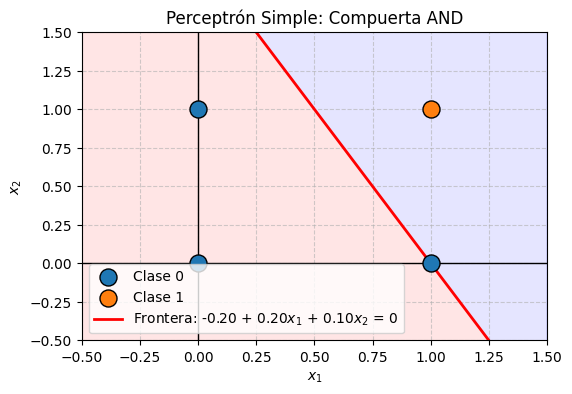

Entrenando OR...


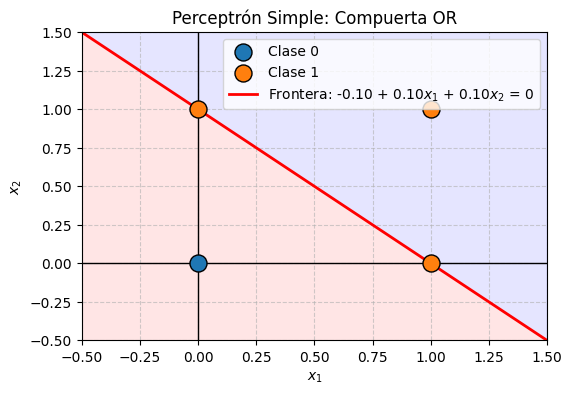

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

class PerceptronSimple:
    def __init__(self, tasa_aprendizaje=0.1):
        # w0 (sesgo), w1, w2
        self.pesos = np.zeros(3)
        self.tasa_aprendizaje = tasa_aprendizaje

    def entrenar(self, X, d, max_epocas=100):
        for _ in range(max_epocas):
            hubo_cambios = False
            for x_i, d_i in zip(X, d):
                # Añadimos x0 = 1 para el peso w0 (sesgo)
                x_ext = np.insert(x_i, 0, 1.0)
                y_out = 1 if np.dot(self.pesos, x_ext) >= 0 else 0
                error = d_i - y_out

                if error != 0:
                    self.pesos += self.tasa_aprendizaje * error * x_ext
                    hubo_cambios = True
            if not hubo_cambios:
                break

def graficar_frontera_perceptron(compuerta, X, d, perceptron):
    plt.figure(figsize=(6, 4))

    # Graficar los puntos de las entradas lógicas
    for idx, clase in enumerate(np.unique(d)):
        plt.scatter(X[d == clase, 0], X[d == clase, 1],
                    label=f'Clase {clase}', s=150, edgecolor='k', zorder=3)

    # Definir el rango del plano
    x_min, x_max = -0.5, 1.5
    x1_val = np.array([x_min, x_max])

    # Despejar x2 de la ecuación: w0 + w1*x1 + w2*x2 = 0
    # x2 = (-w0 - w1*x1) / w2
    w0, w1, w2 = perceptron.pesos

    if w2 != 0:
        x2_val = (-w0 - w1 * x1_val) / w2
        plt.plot(x1_val, x2_val, 'r-', linewidth=2,
                 label=f'Frontera: {w0:.2f} + {w1:.2f}$x_1$ + {w2:.2f}$x_2$ = 0')

        # Sombrear las áreas de decisión
        plt.fill_between(x1_val, x2_val, -2, color='red', alpha=0.1)
        plt.fill_between(x1_val, x2_val, 2, color='blue', alpha=0.1)

    plt.xlim(-0.5, 1.5)
    plt.ylim(-0.5, 1.5)

    # Dibujar ejes
    plt.axhline(0, color='black', linewidth=1)
    plt.axvline(0, color='black', linewidth=1)

    plt.title(f'Perceptrón Simple: Compuerta {compuerta}')
    plt.xlabel('$x_1$')
    plt.ylabel('$x_2$')
    plt.legend(loc='best')
    plt.grid(True, linestyle='--', alpha=0.6, zorder=0)
    plt.show()

# ==========================================
# Ejecutar y graficar
# ==========================================
if __name__ == "__main__":
    X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])

    # Entrenar y graficar AND
    print("Entrenando AND...")
    d_and = np.array([0, 0, 0, 1])
    p_and = PerceptronSimple()
    p_and.entrenar(X, d_and)
    graficar_frontera_perceptron("AND", X, d_and, p_and)

    # Entrenar y graficar OR
    print("Entrenando OR...")
    d_or = np.array([0, 1, 1, 1])
    p_or = PerceptronSimple()
    p_or.entrenar(X, d_or)
    graficar_frontera_perceptron("OR", X, d_or, p_or)